**setup**

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from fxml import config
from fxml.db.connection import connect
from fxml.db.schema import init_db
from fxml.evaluation.daily_backtest import run_daily_portfolio
from fxml.evaluation.plots import apply_style, equity_curve
from fxml.training.daily_trend import (RECORDED_FROM, in_period, load_daily_pairs, provenance,
                                       run_period)

apply_style()
conn = connect()
init_db(conn)
PREREG = config.PROJECT_ROOT / "docs" / "preregistration-daily-trend.md"


**load the daily bars**

In [2]:
pairs = load_daily_pairs(conn, config.SYMBOLS)
pd.DataFrame({s: {"days": len(d), "first": d.index[0].date(), "last": d.index[-1].date()}
              for s, d in pairs.items()}).T


,days,first,last
EURUSD,7245,1999-01-04,2026-10-15
GBPUSD,7246,1999-01-04,2026-10-15
AUDUSD,7244,1999-01-04,2026-10-15
USDCAD,7247,1999-01-04,2026-10-15
USDCHF,7242,1999-01-04,2026-10-15
NZDUSD,7243,1999-01-03,2026-10-15
EURGBP,7241,1999-01-04,2026-10-15
USDJPY,7245,1999-01-04,2026-10-15
EURJPY,7119,1999-01-04,2026-10-15
GBPJPY,7246,1999-01-04,2026-10-15


**the development run, 2001-2014 (run this cell once; it is logged)**

In [3]:
info = provenance(config.PROJECT_ROOT, PREREG)
print(info)
dev = run_period(conn, pairs, config.POINT_SIZES, "dev", info,
                 notes="pre-registered development run")
print("saved as run", dev["run_id"])


{'git_commit': 'b05a3e8ba9f668090828d558fae34c2d30e1be5e', 'git_dirty': True, 'preregistration_sha256': '06d71e56bc55c7e18b411a3577cb89508098a07d0f3dd50e0820858925dd081c'}
saved as run 13


**the verdict against the pass marks**

In [4]:
def mark(ok):
    return "PASS" if ok else "FAIL"


t, b, v = dev["targeted"], dev["baseline"], dev["verdict"]
print(f"1. net Sharpe {t['sharpe']:.2f} (90% interval {t['sharpe_ci90_low']:.2f} to "
      f"{t['sharpe_ci90_high']:.2f}), need >= 0.40: {mark(v['sharpe'])}")
print(f"4. max drawdown {t['max_drawdown']:.1%}, need >= -25%: {mark(v['drawdown'])}")
print(f"5. vs equal notional: Sharpe {t['sharpe']:.2f} against {b['sharpe']:.2f}, drawdown "
      f"{t['max_drawdown']:.1%} against {b['max_drawdown']:.1%}: {mark(v['vol_targeting'])}")
print(f"\nall development bars: {mark(v['all'])}")
print(f"\ngross Sharpe {t['gross_sharpe']:.2f}, cost {t['cost_per_year']:.2%} a year, "
      f"annual return {t['annual_return']:.1%}, annual vol {t['annual_vol']:.1%}")
print(f"exposure: median {t['exposure_median']:.1f}x, max {t['exposure_max']:.1f}x capital")


1. net Sharpe 0.23 (90% interval -0.20 to 0.65), need >= 0.40: FAIL
4. max drawdown -28.4%, need >= -25%: FAIL
5. vs equal notional: Sharpe 0.23 against 0.14, drawdown -28.4% against -13.4%: PASS

all development bars: FAIL

gross Sharpe 0.35, cost 1.20% a year, annual return 2.4%, annual vol 10.4%
exposure: median 1.7x, max 6.8x capital


**by year and by pair**

In [5]:
print((pd.Series(dev["yearly_net"]) * 100).round(1).to_string())
print()
print(pd.Series(dev["per_pair_sharpe"]).round(2).to_string())


2001   -15.5
2002     2.5
2003    16.0
2004     1.3
2005    -6.0
2006    -4.3
2007     5.8
2008    20.9
2009     2.5
2010     4.0
2011    -8.2
2012     2.6
2013     7.1
2014     4.9

EURUSD    0.62
GBPUSD    0.12
AUDUSD    0.02
USDCAD   -0.08
USDCHF    0.07
NZDUSD    0.29
EURGBP   -0.27
USDJPY    0.20
EURJPY    0.23
GBPJPY   -0.03
AUDJPY    0.15


**the equity curve**

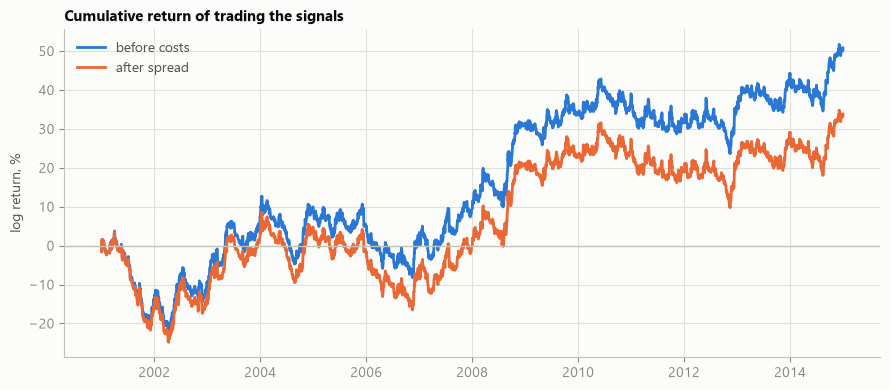

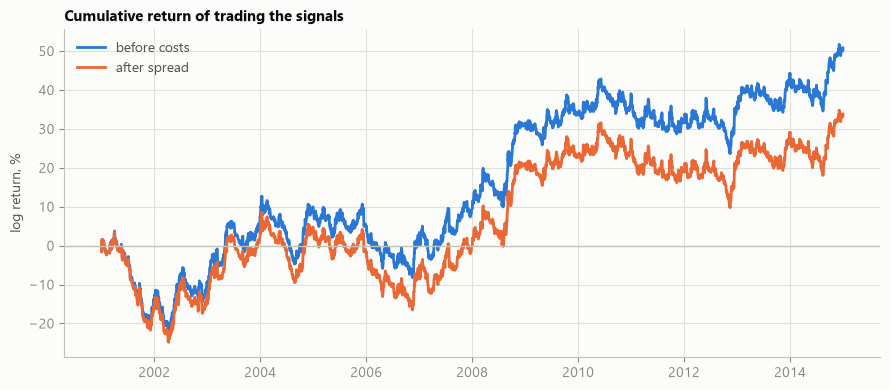

In [6]:
portfolio = run_daily_portfolio(pairs, config.POINT_SIZES, RECORDED_FROM)
gross = in_period(portfolio.daily["gross"], "dev").cumsum()
net = in_period(portfolio.daily["net"], "dev").cumsum()
equity_curve(gross, net)
